In [ ]:
!pip install xgboost pandas numpy scikit-learn joblib matplotlib seaborn

In [ ]:
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [ ]:
uploaded = files.upload()

Saving cloud_task_scheduling_dataset.csv to cloud_task_scheduling_dataset.csv
Saving cloud_task_scheduling_dataset_20k.csv to cloud_task_scheduling_dataset_20k.csv
Saving dataset_raspi_9000.csv to dataset_raspi_9000.csv


In [ ]:
file_names = list(uploaded.keys())

In [ ]:
# Membaca dan menggabungkan kedua dataset menjadi satu DataFrame besar
df_list = [pd.read_csv(f) for f in file_names]
df_raw = pd.concat(df_list, ignore_index=0) if len(df_list) > 1 else df_list[0]
df_raw = pd.concat(df_list, ignore_index=True)

print(f"\nBerhasil menggabungkan {len(file_names)} file. Total Data Mentah: {len(df_raw)} baris.")


Berhasil menggabungkan 3 file. Total Data Mentah: 30000 baris.


DATA CLEANING

In [ ]:
df_raw.isnull()

,Task_ID,CPU_Usage (%),RAM_Usage (MB),Disk_IO (MB/s),Network_IO (MB/s),Priority,VM_ID,Execution_Time (s),Target (Optimal Scheduling)
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
29995,True,False,False,False,False,False,True,False,False
29996,True,False,False,False,False,False,True,False,False
29997,True,False,False,False,False,False,True,False,False
29998,True,False,False,False,False,False,True,False,False


In [ ]:
df_raw.isnull().sum().sum()

np.int64(18000)

In [ ]:
print(df_raw.isnull().sum())

Task_ID                        9000
CPU_Usage (%)                     0
RAM_Usage (MB)                    0
Disk_IO (MB/s)                    0
Network_IO (MB/s)                 0
Priority                          0
VM_ID                          9000
Execution_Time (s)                0
Target (Optimal Scheduling)       0
dtype: int64


In [ ]:
df_clean = df_raw.dropna().copy()
df_clean = df_clean.drop(columns=['Task_ID', 'VM_ID'], errors='ignore')

In [ ]:
df_clean = df_clean.rename(columns={
    'CPU_Usage (%)': 'cpu_usage',
    'RAM_Usage (MB)': 'ram_usage',
    'Disk_IO (MB/s)': 'throughput',
    'Network_IO (MB/s)': 'network_bandwidth',
    'Execution_Time (s)': 'latency',
    'Priority': 'queue_length',
    'Target (Optimal Scheduling)': 'decision_label'
})

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21000 entries, 0 to 20999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   cpu_usage          21000 non-null  float64
 1   ram_usage          21000 non-null  float64
 2   throughput         21000 non-null  float64
 3   network_bandwidth  21000 non-null  float64
 4   queue_length       21000 non-null  int64  
 5   latency            21000 non-null  float64
 6   decision_label     21000 non-null  int64  
dtypes: float64(5), int64(2)
memory usage: 1.3 MB


EDA

In [ ]:
df_clean.head()

,cpu_usage,ram_usage,throughput,network_bandwidth,queue_length,latency,decision_label
0,37.0,2612.0,55.0,40.0,2,1.27,1
1,86.0,11761.0,55.0,12.0,3,3.71,1
2,44.0,4610.0,6.0,1.0,2,8.53,0
3,82.0,12604.0,29.0,18.0,3,7.31,0
4,59.0,15945.0,54.0,11.0,1,1.76,1


In [ ]:
df_clean.tail()

,cpu_usage,ram_usage,throughput,network_bandwidth,queue_length,latency,decision_label
20995,65.0,11319.0,99.0,19.0,3,8.82,0
20996,93.0,13682.0,83.0,38.0,2,1.65,1
20997,49.0,8034.0,45.0,39.0,2,3.34,1
20998,48.0,6321.0,90.0,24.0,2,5.99,0
20999,35.0,12426.0,75.0,18.0,1,5.94,0


/tmp/ipykernel_326/1512327056.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='decision_label', data=df_clean, palette='Set2')


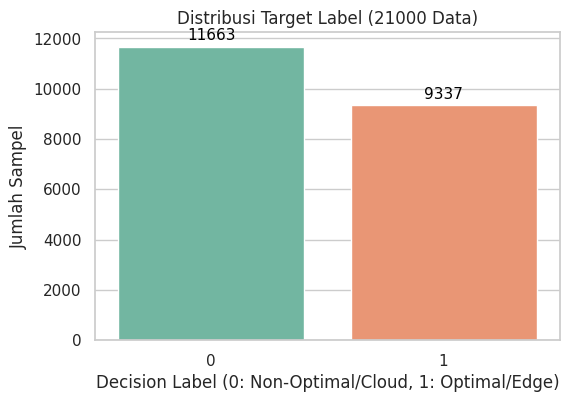

In [ ]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='decision_label', data=df_clean, palette='Set2')
plt.title(f'Distribusi Target Label ({len(df_clean)} Data)')
plt.xlabel('Decision Label (0: Non-Optimal/Cloud, 1: Optimal/Edge)')
plt.ylabel('Jumlah Sampel')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')
plt.show()

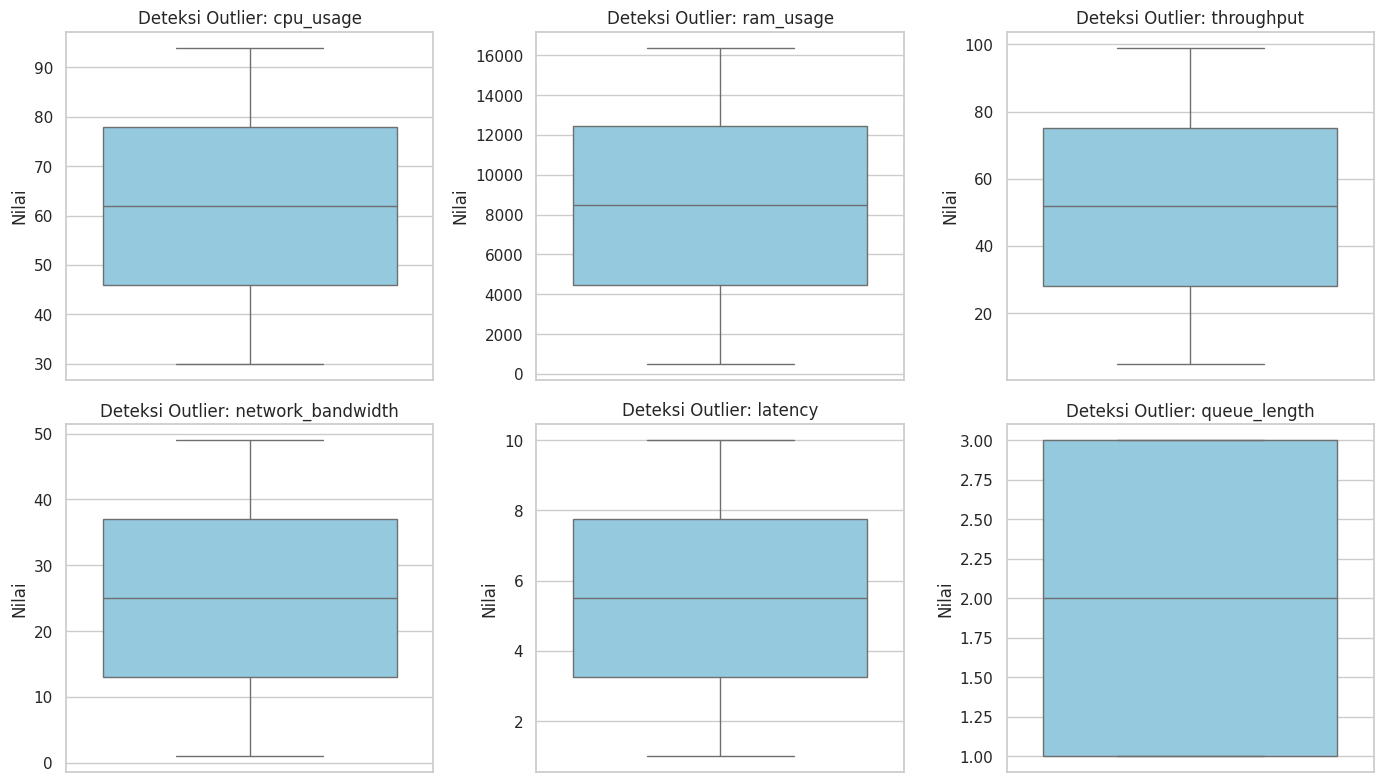

In [ ]:
features = ['cpu_usage', 'ram_usage', 'throughput', 'network_bandwidth', 'latency', 'queue_length']

plt.figure(figsize=(14, 8))
for i, col in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_clean[col], color='skyblue')
    plt.title(f'Deteksi Outlier: {col}')
    plt.ylabel('Nilai')

plt.tight_layout()
plt.show()

SPLIT

In [ ]:
X = df_clean.drop(columns=['decision_label'])
y = df_clean['decision_label']

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [ ]:
print(f"Data Latih (Train Set)        : {len(X_train)} baris")
print(f"Data Validasi (Validation Set) : {len(X_val)} baris")
print(f"Data Uji Akhir (Test Set)      : {len(X_test)} baris")

Data Latih (Train Set)        : 16800 baris
Data Validasi (Validation Set) : 2100 baris
Data Uji Akhir (Test Set)      : 2100 baris


TRAINING PROCESS

In [ ]:
model_xgboost = XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.05,
    eval_metric='logloss',
    random_state=42
)

# Training dengan pemantauan validation set
eval_set = [(X_train, y_train), (X_val, y_val)]
model_xgboost.fit(X_train, y_train, eval_set=eval_set, verbose=False)

print("Training selesai.")

Training selesai.


EVALUASI

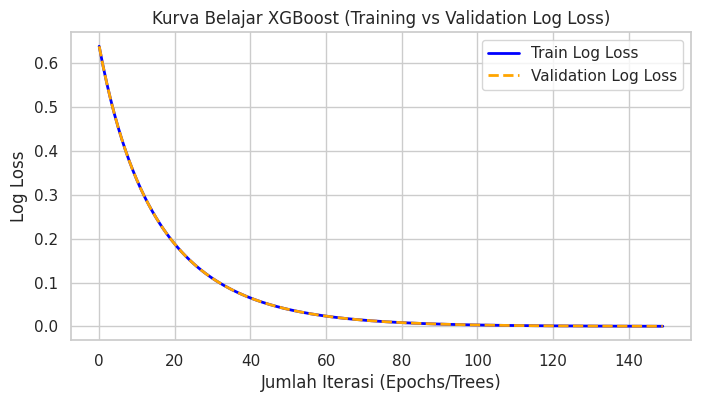

In [ ]:
#Plot Kurva Belajar (Train vs Validation Log Loss)
results = model_xgboost.evals_result()
epochs = len(results['validation_0']['logloss'])
x_axis = range(0, epochs)

plt.figure(figsize=(8, 4))
plt.plot(x_axis, results['validation_0']['logloss'], label='Train Log Loss', color='blue', linewidth=2)
plt.plot(x_axis, results['validation_1']['logloss'], label='Validation Log Loss', color='orange', linewidth=2, linestyle='--')
plt.title('Kurva Belajar XGBoost (Training vs Validation Log Loss)')
plt.xlabel('Jumlah Iterasi (Epochs/Trees)')
plt.ylabel('Log Loss')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
y_pred = model_xgboost.predict(X_test)
print(f"\nAkurasi Akhir Test Set: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Akurasi Akhir Test Set: 100.00%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1167
           1       1.00      1.00      1.00       933

    accuracy                           1.00      2100
   macro avg       1.00      1.00      1.00      2100
weighted avg       1.00      1.00      1.00      2100



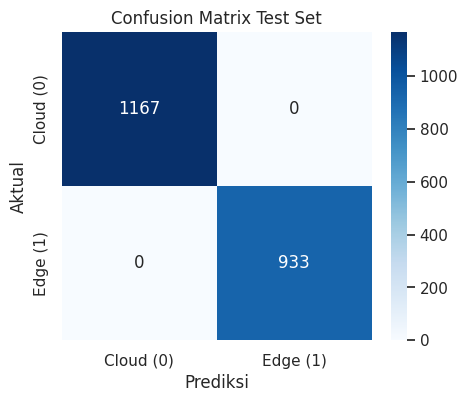

In [ ]:
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cloud (0)', 'Edge (1)'], yticklabels=['Cloud (0)', 'Edge (1)'])
plt.title('Confusion Matrix Test Set')
plt.ylabel('Aktual')
plt.xlabel('Prediksi')
plt.show()

SIMPAN MODEL

In [ ]:
joblib.dump(model_xgboost, 'model_orchestration.pkl')
print("File 'model_orchestration.pkl' berhasil dibuat.")

File 'model_orchestration.pkl' berhasil dibuat.


SIMULASI UJI SAMPEL

In [ ]:
#Ambil 10 sampel acak dari Test Set
df_simulasi = X_test.sample(n=10, random_state=42).copy()
y_aktual = y_test.loc[df_simulasi.index].values

In [ ]:
# Lakukan prediksi menggunakan model XGBoost
y_prediksi = model_xgboost.predict(df_simulasi)

In [ ]:
# Buat DataFrame Perbandingan
df_simulasi['Target_Aktual'] = y_aktual
df_simulasi['Prediksi_AI'] = y_prediksi

In [ ]:
# Tambahkan status apakah prediksinya cocok atau tidak
df_simulasi['Status_Prediksi'] = ['✅ Tepat' if a == p else '❌ Salah' for a, p in zip(y_aktual, y_prediksi)]

In [ ]:
# Tampilkan hasil tabel perbandingan
print("\nTabel Hasil Pengujian 10 Sampel Acak:")
display(df_simulasi[['cpu_usage', 'ram_usage', 'throughput', 'network_bandwidth', 'latency', 'queue_length', 'Target_Aktual', 'Prediksi_AI', 'Status_Prediksi']])


Tabel Hasil Pengujian 10 Sampel Acak:


,cpu_usage,ram_usage,throughput,network_bandwidth,latency,queue_length,Target_Aktual,Prediksi_AI,Status_Prediksi
9823,60.0,4503.0,40.0,33.0,3.14,1,1,1,✅ Tepat
1668,49.0,9869.0,44.0,41.0,7.61,3,0,0,✅ Tepat
20741,61.0,3727.0,44.0,42.0,2.32,2,1,1,✅ Tepat
4374,71.0,4161.0,43.0,13.0,2.87,2,1,1,✅ Tepat
9935,63.0,5277.0,72.0,3.0,6.21,2,0,0,✅ Tepat
16300,87.0,7972.0,60.0,20.0,9.37,3,0,0,✅ Tepat
20981,94.0,8034.0,26.0,36.0,9.70,1,0,0,✅ Tepat
5606,81.0,4683.0,30.0,25.0,1.03,1,1,1,✅ Tepat
3238,42.0,3569.0,29.0,44.0,1.07,1,1,1,✅ Tepat
19957,73.0,1030.0,87.0,23.0,5.89,1,0,0,✅ Tepat


<Figure size 800x500 with 0 Axes>

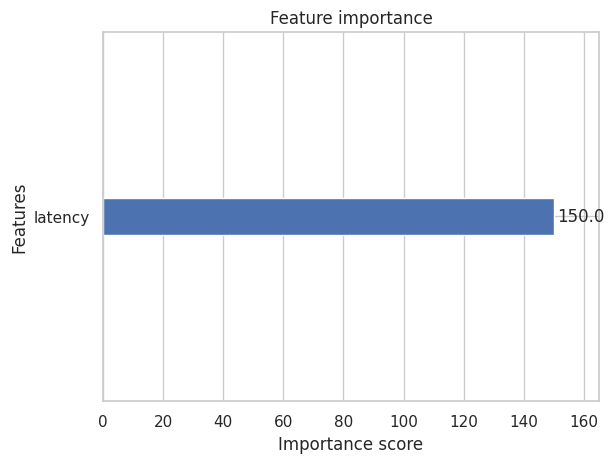

In [ ]:
import joblib
import matplotlib.pyplot as plt
from xgboost import plot_importance

# 1. Muat file model .pkl
model = joblib.load("model_orchestration.pkl")

# 2. Tampilkan Feature Importance
plt.figure(figsize=(8, 5))
plot_importance(model)
plt.show()